In [5]:
from __future__ import division
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time
from astropy.constants import G
from astropy import units as u
from galpy.potential import ChandrasekharDynamicalFrictionForce as CDFF, NFWPotential, vcirc, FDMDynamicalFrictionForce as FDM_DF
from galpy.orbit import Orbit
from colossus.halo import concentration, profile_nfw
from colossus.cosmology import cosmology
from joblib import Parallel, delayed
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable
from halotools.sim_manager import FakeSim
from halotools.empirical_models import PrebuiltSubhaloModelFactory
cosmology.setCosmology('planck15')
import matplotlib.lines as mlines
from scipy.stats import gaussian_kde
from matplotlib.ticker import AutoMinorLocator
from matplotlib.ticker import MultipleLocator

def mass_from_mag(MAG_GC):
    return 1.8 * 10**(-0.4 * (MAG_GC + 0.5 - 4.83))

def count_unique(arr):
    return len(set(arr))

Rlimit=0.2 #kpc
MAGlimit = -8

file_path = "ERO_Fornax_GCs_results_for_Pierre_Feb2026.csv"
df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()
print(df)

logMs=np.log10(df["logMstar_host"].to_numpy())
#logMs=df["logMstar_host"].to_numpy()
IDgal=df["gal_name"].to_numpy()
MAG_GC=df["GC_VIS_abs"].to_numpy()
RGC=df["GC_dist_kpc"].to_numpy()
print("total number of GCs :",len(RGC))
print('total number of galaxies :',count_unique(IDgal))


sola=np.where(MAG_GC<=MAGlimit)[0]
logMs=logMs[sola]
RGC=RGC[sola]
MAG_GC=MAG_GC[sola]
IDgal=IDgal[sola]

sol=np.where(RGC>Rlimit)[0]
logMs=logMs[sol]
MAG_GC=MAG_GC[sol]
RGC=RGC[sol]
IDgal=IDgal[sol]
MGC=mass_from_mag(MAG_GC)

print("final number of GCs ",len(RGC))
print('final number of galaxies (contening GCs):',count_unique(IDgal))
df_clean = pd.DataFrame({
    "galaxy": IDgal,
    "R": RGC,
    "MAG": MAG_GC,
    "logMs": logMs})

groups = df_clean.groupby("galaxy")
"""
for name, g in groups:
    print(f"Galaxie : {name} -> nombre de GC : {len(g)}")"""

           gal_name         ra        dec  logMstar_host  Re_kpc_host  \
0    FORNAX-DWARF-3  54.268426 -35.585436   2.212693e+08     1.220224   
1    FORNAX-DWARF-3  54.270029 -35.586834   2.212693e+08     1.220224   
2    FORNAX-DWARF-3  54.263074 -35.591709   2.212693e+08     1.220224   
3    FORNAX-DWARF-3  54.271656 -35.592972   2.212693e+08     1.220224   
4    FORNAX-DWARF-3  54.267289 -35.587450   2.212693e+08     1.220224   
..              ...        ...        ...            ...          ...   
75  FORNAX-DWARF-27  54.413306 -35.388074   4.921519e+06     0.605256   
76  FORNAX-DWARF-27  54.410504 -35.389804   4.921519e+06     0.605256   
77  FORNAX-DWARF-28  53.778335 -35.449359   5.967634e+05     0.852268   
78  FORNAX-DWARF-28  53.767476 -35.453414   5.967634e+05     0.852268   
79  FORNAX-DWARF-28  53.770381 -35.444481   5.967634e+05     0.852268   

    GC_dist_kpc  GC_VIS_abs  GC_back_prob  d_RA_GC_kpc  d_DEC_GC_kpc  
0      1.687586   -9.245816      0.050644    -0.1705

'\nfor name, g in groups:\n    print(f"Galaxie : {name} -> nombre de GC : {len(g)}")'

In [3]:
ts=np.linspace(0,10,1001)*u.Gyr
rhm=0.01 #kpc
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
df=pd.DataFrame({"ID":IDgal,"R":RGC,"MAG":MAG_GC,"logMs":logMs})
groups=df.groupby("ID")

m22_1 = {}
for name, g in groups:
    R = g["R"].to_numpy()
    N_amas=len(R)
    MAG = g["MAG"].to_numpy()
    logM = g["logMs"].iloc[0]
    M = mass_from_mag(MAG)
    Mg = 10**model.mean_log_halo_mass(logM)
    Mh = Mg * 0.704
    c = concentration.concentration(Mh,'vir',0,model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
    rs = p_nfw.par['rs']/0.704
    A = np.log(1+c)-c/(1+c)
    NFW_pot = NFWPotential(amp=Mg/A*u.Msun, a=rs*u.kpc)

    os = [[r*u.kpc,0*u.km/u.s,vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg]   for r in R]

    def cdm_local(i):
        orb = Orbit(os[i])
        cdf = CDFF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
        orb.integrate(ts, NFW_pot+cdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    valid = np.where([cdm_local(i) for i in range(len(R))])[0]
    R = R[valid]
    M = M[valid]
    os = [os[i] for i in valid]
    #print(f"Galaxie : {name} -> {len(R)}/{len(g)} amas conservés ({len(R)/len(g)*100:.2f}%)")
    def test_local(i, m22):
        orb = Orbit(os[i])
        fdf = FDM_DF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc,  dens=NFW_pot, m=(m22*1e-22)*u.eV)
        orb.integrate(ts, NFW_pot + fdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    def find_m22(i, lo=0.01, hi=100.0, eps=0.01):
        while hi-lo > eps:
            mid = 0.5*(hi+lo)
            if test_local(i, mid):
                hi = mid
            else:
                lo = mid
        return 0.5*(hi+lo)

    m22_1[name] = np.array([find_m22(i) for i in range(len(R))])


m22_2 = {}
for name, g in groups:
    R = g["R"].to_numpy()*2/np.sqrt(3)
    N_amas=len(R)
    MAG = g["MAG"].to_numpy()
    logM = g["logMs"].iloc[0]
    M = mass_from_mag(MAG)
    Mg = 10**model.mean_log_halo_mass(logM)
    Mh = Mg * 0.704
    c = concentration.concentration(Mh,'vir',0,model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
    rs = p_nfw.par['rs']/0.704
    A = np.log(1+c)-c/(1+c)
    NFW_pot = NFWPotential(amp=Mg/A*u.Msun, a=rs*u.kpc)

    os = [[r*u.kpc,0*u.km/u.s,vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg]   for r in R]

    def cdm_local(i):
        orb = Orbit(os[i])
        cdf = CDFF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
        orb.integrate(ts, NFW_pot+cdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    valid = np.where([cdm_local(i) for i in range(len(R))])[0]
    R = R[valid]
    M = M[valid]
    os = [os[i] for i in valid]
    #print(f"Galaxie : {name} -> {len(R)}/{len(g)} amas conservés ({len(R)/len(g)*100:.2f}%)")
    def test_local(i, m22):
        orb = Orbit(os[i])
        fdf = FDM_DF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc,  dens=NFW_pot, m=(m22*1e-22)*u.eV)
        orb.integrate(ts, NFW_pot + fdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    def find_m22(i, lo=0.01, hi=100.0, eps=0.01):
        while hi-lo > eps:
            mid = 0.5*(hi+lo)
            if test_local(i, mid):
                hi = mid
            else:
                lo = mid
        return 0.5*(hi+lo)

    m22_2[name] = np.array([find_m22(i) for i in range(len(R))])

m1=[]
m2=[]
for name, m22 in m22_1.items():
    if len(m22) > 0:
        print(f"Galaxy : {name} m22 : {m22} , min:{np.min(m22)}") #R2D
        m1.append(np.min(m22))

for name, m22 in m22_2.items():
    if len(m22) > 0:
        print(f"Galaxy : {name} m22 : {m22} , min:{np.min(m22)}") #R3D
        m2.append(np.min(m22))

Galaxy : FORNAX-DWARF-10 m22 : [7.01918671] , min:7.019186706542969
Galaxy : FORNAX-DWARF-13 m22 : [1.19701508] , min:1.1970150756835936
Galaxy : FORNAX-DWARF-20 m22 : [2.59458038] , min:2.5945803833007814
Galaxy : FORNAX-DWARF-28 m22 : [1.6913504] , min:1.6913504028320312
Galaxy : FORNAX-DWARF-4 m22 : [4.96250763] , min:4.962507629394532
Galaxy : FORNAX-DWARF-6 m22 : [3.34523773 4.42545197] , min:3.3452377319335938
Galaxy : FORNAX-DWARF-8 m22 : [4.86486115 6.46382233] , min:4.864861145019532
Galaxy : FORNAX-DWARF-10 m22 : [12.77422638] , min:12.774226379394534
Galaxy : FORNAX-DWARF-13 m22 : [1.34958771] , min:1.3495877075195313
Galaxy : FORNAX-DWARF-20 m22 : [3.33913483] , min:3.3391348266601564
Galaxy : FORNAX-DWARF-28 m22 : [2.13686249] , min:2.1368624877929685
Galaxy : FORNAX-DWARF-4 m22 : [8.25197357] , min:8.251973571777345
Galaxy : FORNAX-DWARF-6 m22 : [4.95640472 7.05580414] , min:4.956404724121093
Galaxy : FORNAX-DWARF-8 m22 : [ 9.29557037 11.51092499] , min:9.295570373535156


In [ ]:
print("total of Galaxies :", len(m1),len(m2))
print("total of GCs :",sum(map(len, m22_1.values())),sum(map(len, m22_2.values())))

In [6]:
#calcul pour r2D et 3D avec excentricité
e=0.5

m22_e1 = {}
for name, g in groups:
    R = g["R"].to_numpy()
    N_amas=len(R)
    MAG = g["MAG"].to_numpy()
    logM = g["logMs"].iloc[0]
    M = mass_from_mag(MAG)
    Mg = 10**model.mean_log_halo_mass(logM)
    Mh = Mg * 0.704
    c = concentration.concentration(Mh,'vir',0,model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
    rs = p_nfw.par['rs']/0.704
    A = np.log(1+c)-c/(1+c)
    NFW_pot = NFWPotential(amp=Mg/A*u.Msun, a=rs*u.kpc)

    os = [[r*u.kpc,0*u.km/u.s,np.sqrt(1+e)*vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg]   for r in R]

    def cdm_local(i):
        orb = Orbit(os[i])
        cdf = CDFF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
        orb.integrate(ts, NFW_pot+cdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    valid = np.where([cdm_local(i) for i in range(len(R))])[0]
    R = R[valid]
    M = M[valid]
    os = [os[i] for i in valid]
    #print(f"Galaxie : {name} -> {len(R)}/{len(g)} amas conservés ({len(R)/len(g)*100:.2f}%)")
    def test_local(i, m22):
        orb = Orbit(os[i])
        fdf = FDM_DF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc,  dens=NFW_pot, m=(m22*1e-22)*u.eV)
        orb.integrate(ts, NFW_pot + fdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    def find_m22(i, lo=0.01, hi=100.0, eps=0.01):
        while hi-lo > eps:
            mid = 0.5*(hi+lo)
            if test_local(i, mid):
                hi = mid
            else:
                lo = mid
        return 0.5*(hi+lo)

    m22_e1[name] = np.array([find_m22(i) for i in range(len(R))])


m22_e2 = {}
for name, g in groups:
    R = g["R"].to_numpy()*2/np.sqrt(3)
    N_amas=len(R)
    MAG = g["MAG"].to_numpy()
    logM = g["logMs"].iloc[0]
    M = mass_from_mag(MAG)
    Mg = 10**model.mean_log_halo_mass(logM)
    Mh = Mg * 0.704
    c = concentration.concentration(Mh,'vir',0,model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
    rs = p_nfw.par['rs']/0.704
    A = np.log(1+c)-c/(1+c)
    NFW_pot = NFWPotential(amp=Mg/A*u.Msun, a=rs*u.kpc)

    os = [[r*u.kpc,0*u.km/u.s,np.sqrt(1+e)*vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg]   for r in R]

    def cdm_local(i):
        orb = Orbit(os[i])
        cdf = CDFF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
        orb.integrate(ts, NFW_pot+cdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    valid = np.where([cdm_local(i) for i in range(len(R))])[0]
    R = R[valid]
    M = M[valid]
    os = [os[i] for i in valid]
    #print(f"Galaxie : {name} -> {len(R)}/{len(g)} amas conservés ({len(R)/len(g)*100:.2f}%)")
    def test_local(i, m22):
        orb = Orbit(os[i])
        fdf = FDM_DF(GMs=M[i]*u.Msun, rhm=rhm*u.kpc,  dens=NFW_pot, m=(m22*1e-22)*u.eV)
        orb.integrate(ts, NFW_pot + fdf, method='dop853_c')
        return np.min(orb.r(ts)) < Rlimit

    def find_m22(i, lo=0.01, hi=100.0, eps=0.01):
        while hi-lo > eps:
            mid = 0.5*(hi+lo)
            if test_local(i, mid):
                hi = mid
            else:
                lo = mid
        return 0.5*(hi+lo)

    m22_e2[name] = np.array([find_m22(i) for i in range(len(R))])

me1=[]
me2=[]
for name, m22 in m22_e1.items():
    if len(m22) > 0:
        print(f"Galaxy : {name} m22 : {m22} , min:{np.min(m22)}")
        me1.append(np.min(m22))

for name, m22 in m22_e2.items():
    if len(m22) > 0:
        print(f"Galaxy : {name} m22 : {m22} , min:{np.min(m22)}")
        me2.append(np.min(m22))


KeyboardInterrupt: Orbit integration interrupted by CTRL-C (SIGINT)

In [9]:
np.savez("m22_NFW.npz",m2D=m1,m3D=m2,me2D=me1,me3D=me2)
print(me1)

[np.float64(13.45775177001953), np.float64(1.0627511596679686), np.float64(3.3147232055664064), np.float64(2.3382583618164063), np.float64(8.306899719238281), np.float64(4.779420471191406), np.float64(10.491739807128905)]


In [ ]:
kde1 = gaussian_kde(m1)
x1 = np.linspace(min(m1), max(m1), 1000)
y1 = kde1(x1)
kde2 = gaussian_kde(m2)
x2 = np.linspace(min(m2), max(m2), 1000)
y2 = kde2(x2)

kdee1 = gaussian_kde(me1)
xe1 = np.linspace(min(me1), max(me1), 1000)
ye1 = kdee1(xe1)
kdee2 = gaussian_kde(me2)
xe2 = np.linspace(min(me2), max(me2), 1000)
ye2 = kdee2(xe2)
print((me2))

plt.figure(figsize=(8,6))

plt.plot(x1, y1,label=r"$R_{2D}$",alpha=0.6,color="#1f77b4",linewidth=2)
plt.plot(x2, y2,label=r"$R_{3D}$",alpha=0.6,color="#d62728",linewidth=2)

plt.plot(xe1, ye1,label=r"$R_{2D}$ (e=0.5)",alpha=0.6,color="#1f77b4",linestyle=":",linewidth=2)
plt.plot(xe2, ye2,label=r"$R_{3D}$ (e=0.5)",alpha=0.6,color="#d62728",linestyle=":",linewidth=2)

plt.ylabel(r"Probability density",fontsize=12)
plt.xlabel(r"$m_{22}\;[10^{-22}\,\mathrm{eV}]$",fontsize=12)
plt.xlim(0,38)
plt.xticks(np.arange(0,38,5))
plt.yticks(fontsize=10)
ax = plt.gca()
ax.xaxis.set_minor_locator(MultipleLocator(1))
ax.yaxis.set_minor_locator(MultipleLocator(0.01))
ax.tick_params(which="both", direction="in")
ax.tick_params(which="minor", length=3)
plt.grid(True,linestyle="--",linewidth=0.5)

plt.axvline(1.31,linestyle="-",color="#1f77b4",alpha=0.6,linewidth=1)    #r2D e=0          NFW profile
plt.axvline(1.73,linestyle="-",color="#d62728",alpha=0.6,linewidth=1)     #r3D e=0
plt.axvline(1.17,linestyle=":",color="#1f77b4",alpha=0.6,linewidth=1)     #r2D e=0.5         
plt.axvline(1.69,linestyle=":",color="#d62728",alpha=0.6,linewidth=1)     #r3D e=0.5

plt.axvline(1.33,linestyle="-",color="#1f77b4",alpha=0.6,linewidth=1)    #r2D e=0           Core profile
plt.axvline(1.64,linestyle="-",color="#d62728",alpha=0.6,linewidth=1)     #r3D e=0
plt.axvline(1.22,linestyle=":",color="#1f77b4",alpha=0.6,linewidth=1)     #r2D e=0.5         
plt.axvline(1.50,linestyle=":",color="#d62728",alpha=0.6,linewidth=1)     #r23D e=0.5


#plt.text(0.82, 0.78, "- - -  Fornax", transform=plt.gca().transAxes, fontsize=13)
plt.legend(frameon=False,fontsize=15)
plt.savefig("s_histe.png",dpi=300,bbox_inches="tight")
plt.show()


#excentricité 0.5, lire article, et après changer profile matière noire

In [ ]:
for name, m22 in m22_e1.items():
    if len(m22) > 0:
        print(f"Galaxy : {name} m22 : {m22} , min:{np.min(m22)}")

for name, m22 in m22_e2.items():
    if len(m22) > 0:
        print(f"Galaxy : {name} m22 : {m22} , min:{np.min(m22)}")


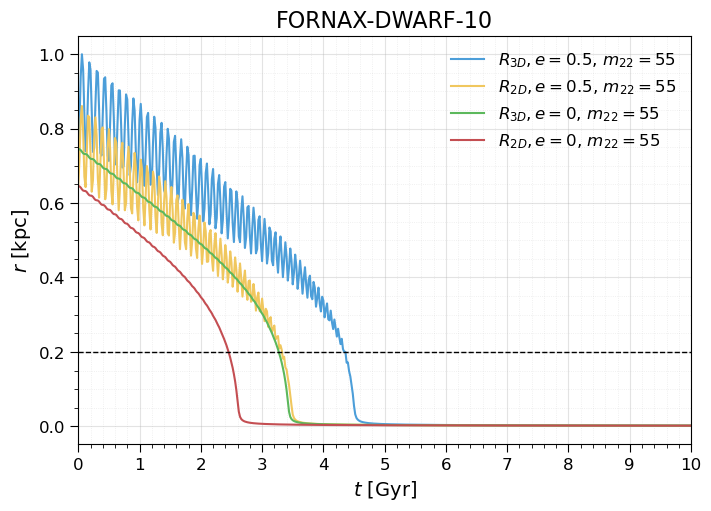

In [14]:
# plot 1 galaxy
ts = np.linspace(0, 10, 501) * u.Gyr
e = 0.5
rhm = 0.01  # kpc
halocat = FakeSim()
model = PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
df = pd.DataFrame({"ID": IDgal, "R": RGC, "MAG": MAG_GC, "logMs": logMs})
target = "FORNAX-DWARF-20"
sel = np.where(IDgal == target)[0]
Rproj = RGC[sel]
Rdeproj = Rproj * 2 / np.sqrt(3)
MGC_fornax = MGC[sel]
g = df.groupby("ID").get_group(target)
logM = g["logMs"].iloc[0]
Mg = 10**model.mean_log_halo_mass(logM)
Mh = Mg * 0.704
c = concentration.concentration(Mh, 'vir', 0, model='prada12')
p_nfw = profile_nfw.NFWProfile(M=Mh, c=c, z=0, mdef='vir')
rs = p_nfw.par['rs'] / 0.704
A = np.log(1 + c) - c / (1 + c)
NFW_pot = NFWPotential(amp=Mg / A * u.Msun, a=rs * u.kpc)
mgc = MGC_fornax[0]
colors = ["#4C9ED9", "#F0C75E", "#5CB85C", "#C44E52"]#5CB85C

m22_list = [55,55,55,55]

configs = [
    {"R": Rdeproj[0], "fac": np.sqrt(1 + e), "label": r"$R_{3D}, e=0.5$", "m22": m22_list[0]},
    {"R": Rproj[0],   "fac": np.sqrt(1 + e), "label": r"$R_{2D}, e=0.5$", "m22": m22_list[1]},
    {"R": Rdeproj[0], "fac": 1.0,           "label": r"$R_{3D}, e=0$",   "m22": m22_list[2]},
    {"R": Rproj[0],   "fac": 1.0,           "label": r"$R_{2D}, e=0$",   "m22": m22_list[3]},]

results = []

for cfg in configs:
    m = (cfg["m22"] * 1e-22) * u.eV  

    o = [
        cfg["R"] * u.kpc,
        0 * u.km / u.s,
        cfg["fac"] * vcirc(NFW_pot, cfg["R"] * u.kpc) * u.km / u.s,
        0 * u.kpc,
        0 * u.km / u.s,
        0 * u.deg
    ]

    orb = Orbit(o)
    fdf = FDM_DF(GMs=mgc * u.Msun, rhm=rhm * u.kpc, dens=NFW_pot, m=m)
    orb.integrate(ts, NFW_pot + fdf, method='dop853_c')
    results.append({"label": cfg["label"] + rf", $m_{{22}}={cfg['m22']}$","r": orb.r(ts)})

# plot
t = ts.value
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
for i, res in enumerate(results):
    ax.plot(t,res["r"],lw=1.5,color=colors[i % len(colors)],label=res["label"])
ax.axhline(0.2, color='black', linestyle='--', lw=1)#, label='0.2 kpc')
ax.set_title('FORNAX-DWARF-10', fontsize=16)
ax.set_xlabel(r'$t\ \mathrm{[Gyr]}$', fontsize=14)
ax.set_ylabel(r'$r\ \mathrm{[kpc]}$', fontsize=14)
ax.set_xlim(0, 10)
ax.set_xticks(np.arange(0, 10.5, 1.0))              # ticks majeurs
ax.set_xticks(np.arange(0, 10.5, 0.5), minor=True)  # ticks mineurs
ax.minorticks_on()

ax.grid(True, which='major', linestyle='-', alpha=0.35, linewidth=0.8)
ax.grid(True, which='minor', linestyle=':', alpha=0.25, linewidth=0.6)

ax.tick_params(axis='both', which='major', labelsize=12, length=6)
ax.tick_params(axis='both', which='minor', length=3)
ax.legend(frameon=False,fontsize=(12))
plt.savefig("FORNAX-DWARF-10_2.png", dpi=300, bbox_inches="tight")
plt.show()

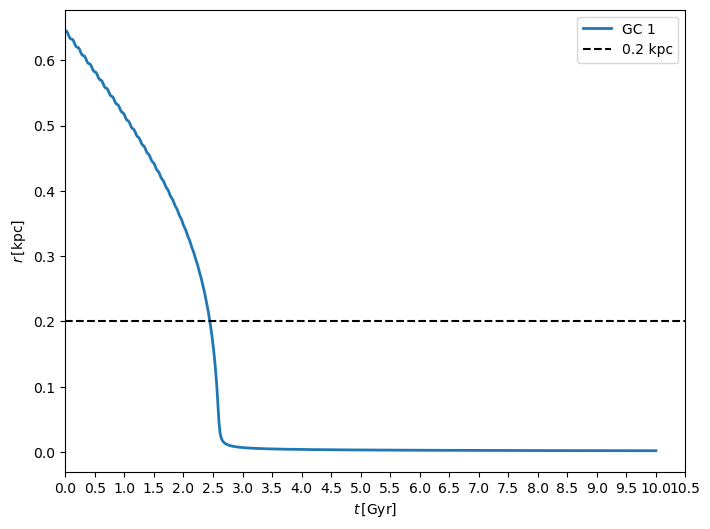

In [11]:
# plot d'une galaxie : FORNAX-DWARF-...

target = "FORNAX-DWARF-20"
sel = np.where(IDgal == target)[0]
RGC_fornax = RGC[sel]
MGC_fornax = MGC[sel]
g = df.groupby("ID").get_group(target)
logM = g["logMs"].iloc[0]
Mg = 10**model.mean_log_halo_mass(logM)
Mh = Mg * 0.704

c = concentration.concentration(Mh, 'vir', 0, model='prada12')
p_nfw = profile_nfw.NFWProfile(M=Mh, c=c, z=0, mdef='vir')
rs = p_nfw.par['rs']/0.704
A = np.log(1+c)-c/(1+c)
NFW_pot = NFWPotential(amp=Mg/A*u.Msun,a=rs*u.kpc)

os = [[r * u.kpc, 0 * u.km/u.s,vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg] for r in RGC_fornax]
all_r = []
for i in range(len(RGC_fornax)):
    orb = Orbit(os[i])
    cdf = CDFF(GMs=MGC_fornax[i]*u.Msun,rhm=rhm * u.kpc,dens=NFW_pot)
    orb.integrate(ts, NFW_pot+cdf, method='dop853_c')
    #print("rmin =", np.min(orb.r(ts)))
    all_r.append(orb.r(ts))

#plot
plt.figure(figsize=(8, 6))
for i, r in enumerate(all_r):
    plt.plot(ts.value, r, lw=2, label=f'GC {i+1}')
plt.axhline(0.2, color='black', ls='--',label="0.2 kpc")
plt.xlabel(r'$t\,[\mathrm{Gyr}]$')
plt.ylabel(r'$r\,[\mathrm{kpc}]$')
plt.xlim(0, 10)
plt.xticks(np.arange(0, 11, 0.5))
plt.legend()
plt.show()

In [13]:
print(RGC_fornax)

[0.64525297]
